In [1]:
## load data
import pandas as pd

df = pd.read_csv('air_quality_dataset.csv')
df

,PM2.5,PM10,NOx,NO2,SO2,VOCs,CO,CO2,CH4,Temperature
0,39.967142,57.926035,116.192213,55.230299,4.531693,75.317261,2.789606,427.674347,1.706105,31.085120
1,101.935672,150.774299,76.826826,79.051618,18.744780,145.083987,1.966569,529.739619,2.492663,33.711103
2,70.996192,138.948796,158.731020,60.466604,14.892239,145.147338,2.626446,499.889443,2.431165,33.778698
3,28.464728,63.643900,25.385343,15.333286,7.647429,130.022319,1.779360,388.283712,1.818563,31.565877
4,78.265276,113.977926,105.644340,59.202337,17.696806,181.713667,3.240533,464.739197,2.597225,32.229835
...,...,...,...,...,...,...,...,...,...,...
495,51.380025,57.573550,31.124630,19.276010,11.167098,104.071502,1.844483,397.418878,1.923525,34.323410
496,46.816837,75.372133,22.174014,18.535162,12.169426,74.802208,1.364096,392.316075,2.157281,26.321361
497,33.909351,88.097250,27.630317,15.653370,7.997326,128.105470,2.319453,378.653347,1.809489,28.964494
498,43.721651,40.847991,27.253977,19.365916,7.218154,106.053329,1.599748,389.878566,1.858964,29.976442


In [3]:
## EDA
print(f'Cek 5 data teratas \n {df.head()} \n')

print(f'Cek tipe data \n {df.dtypes} \n')

print(f'Cek missing values \n {df.isnull().sum()}')

Cek 5 data teratas 
         PM2.5        PM10         NOx        NO2        SO2        VOCs  \
0   39.967142   57.926035  116.192213  55.230299   4.531693   75.317261   
1  101.935672  150.774299   76.826826  79.051618  18.744780  145.083987   
2   70.996192  138.948796  158.731020  60.466604  14.892239  145.147338   
3   28.464728   63.643900   25.385343  15.333286   7.647429  130.022319   
4   78.265276  113.977926  105.644340  59.202337  17.696806  181.713667   

         CO         CO2       CH4  Temperature  
0  2.789606  427.674347  1.706105    31.085120  
1  1.966569  529.739619  2.492663    33.711103  
2  2.626446  499.889443  2.431165    33.778698  
3  1.779360  388.283712  1.818563    31.565877  
4  3.240533  464.739197  2.597225    32.229835   

Cek tipe data 
 PM2.5          float64
PM10           float64
NOx            float64
NO2            float64
SO2            float64
VOCs           float64
CO             float64
CO2            float64
CH4            float64
Temperatu

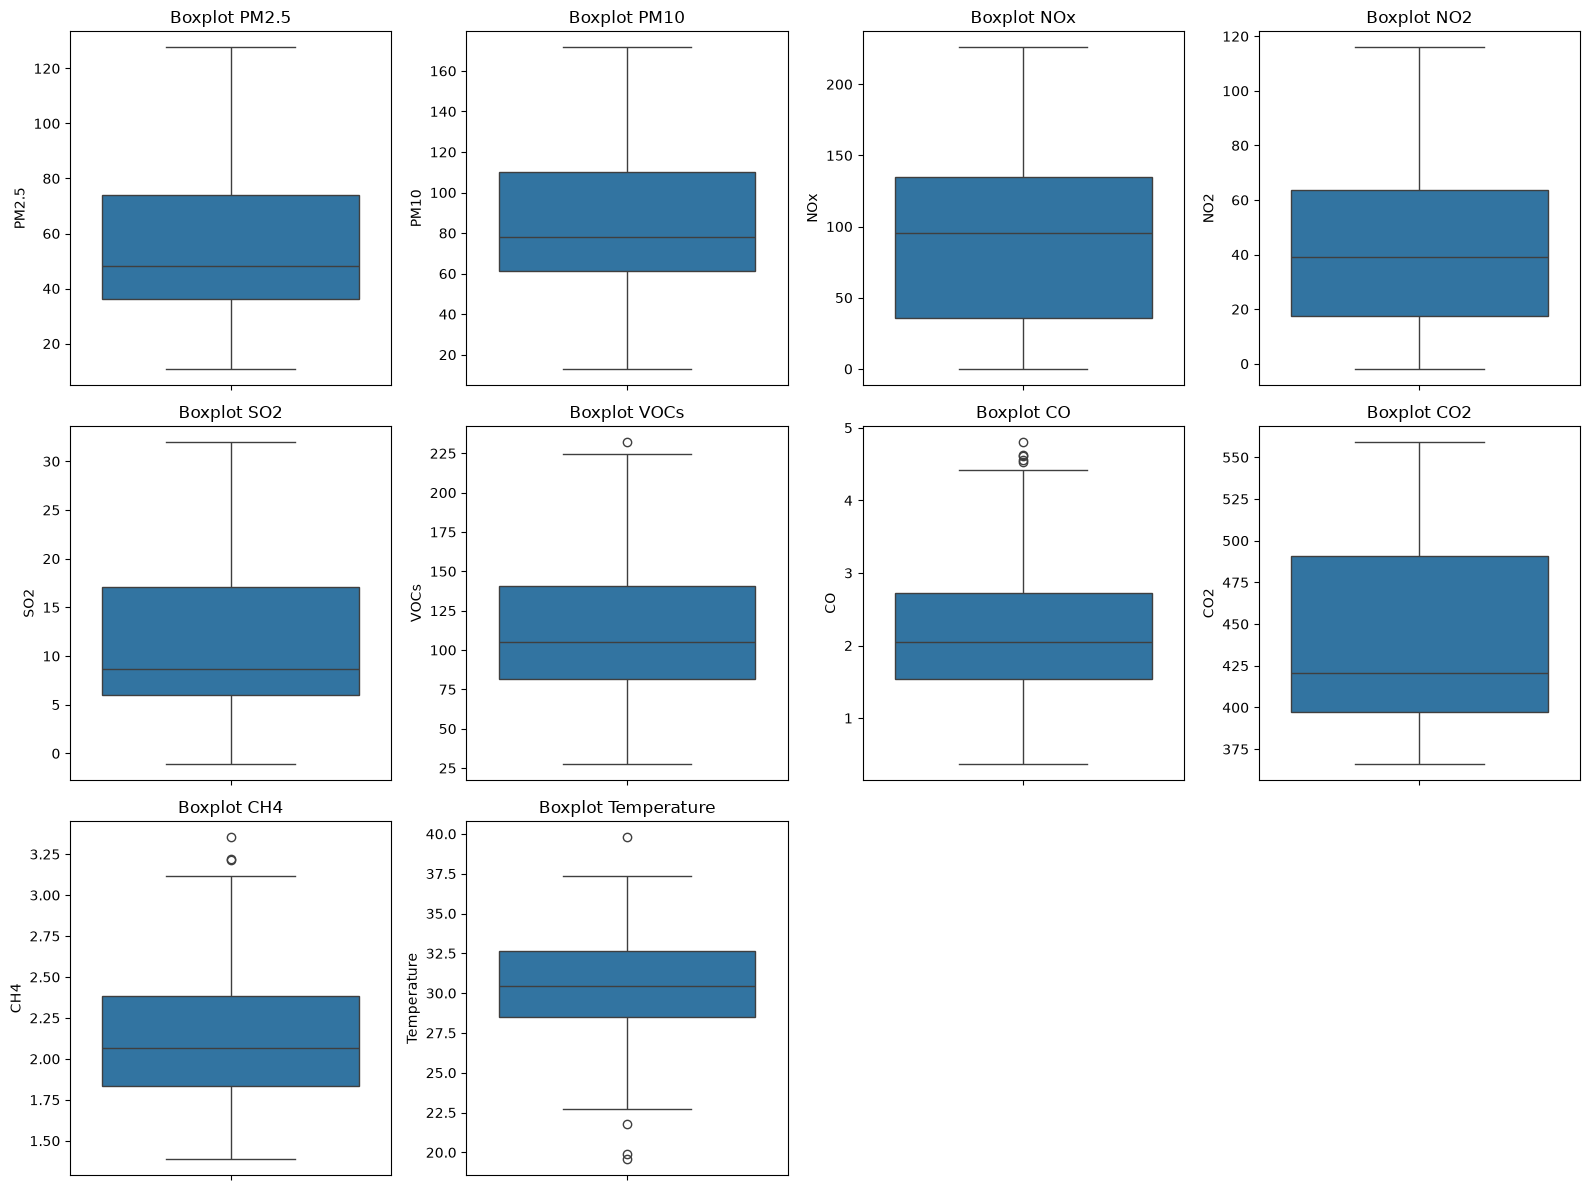

In [4]:
## Outlier
import math
import matplotlib.pyplot as plt
import seaborn as sns

numerical_columns = df.select_dtypes(include='number').columns

## Outlier
n_cols = 4  # jumlah plot per baris, silakan diubah
n_rows = math.ceil(len(numerical_columns) / n_cols)

plt.figure(figsize=(4 * n_cols, 4 * n_rows))

for i, column in enumerate(numerical_columns):
    plt.subplot(n_rows, n_cols, i + 1)
    sns.boxplot(y=df[column])
    plt.title(f'Boxplot {column}')

plt.tight_layout()
plt.show()

In [5]:
## handle outlier
numerical_columns = df.select_dtypes(include='number').columns

Q1 = df[numerical_columns].quantile(0.25)
Q3 = df[numerical_columns].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_mask = (
    (df[numerical_columns] < lower_bound) |
    (df[numerical_columns] > upper_bound)
)

outlier_summary = pd.DataFrame({
    'Outlier Count': outlier_mask.sum(),
    'Percentage': outlier_mask.mean() * 100
})

outlier_summary.sort_values(
    by='Outlier Count',
    ascending=False
)

,Outlier Count,Percentage
CO,5,1.0
Temperature,4,0.8
CH4,3,0.6
VOCs,1,0.2
PM10,0,0.0
PM2.5,0,0.0
SO2,0,0.0
NO2,0,0.0
NOx,0,0.0
CO2,0,0.0


In [13]:
# Feature Selection (X)
X = df.drop(columns=['CO'])

# Target Selection (y)
y = df['CO']

# Cek hasil
print("Features (X):")
print(X.head())

print("\nTarget (y):")
print(y.head())

print("\nX Shape:", X.shape)
print("y Shape:", y.shape)

Features (X):
        PM2.5        PM10         NOx        NO2        SO2        VOCs  \
0   39.967142   57.926035  116.192213  55.230299   4.531693   75.317261   
1  101.935672  150.774299   76.826826  79.051618  18.744780  145.083987   
2   70.996192  138.948796  158.731020  60.466604  14.892239  145.147338   
3   28.464728   63.643900   25.385343  15.333286   7.647429  130.022319   
4   78.265276  113.977926  105.644340  59.202337  17.696806  181.713667   

          CO2       CH4  Temperature  
0  427.674347  1.706105    31.085120  
1  529.739619  2.492663    33.711103  
2  499.889443  2.431165    33.778698  
3  388.283712  1.818563    31.565877  
4  464.739197  2.597225    32.229835  

Target (y):
0    2.789606
1    1.966569
2    2.626446
3    1.779360
4    3.240533
Name: CO, dtype: float64

X Shape: (500, 9)
y Shape: (500,)
